# Análise de Carteira de Investimentos com Python

Este notebook analisa uma carteira formada por 50% PETR4 e 50% VALE3.

A análise inclui:

- Retornos
- Retorno acumulado
- Volatilidade
- Sharpe Ratio
- Correlação
- Drawdown
- Comparação com BOVA11
- Comparação da carteira com o CDI

In [16]:
import pandas as pd
import numpy as np
import yfinance as yf
from bcb import sgs
import matplotlib.pyplot as plt

## Coleta de Dados

Nesta etapa são definidos os ativos e coletados os dados históricos através do Yahoo Finance e do Banco Central do Brasil.

In [17]:
ativos = ["PETR4.SA", "VALE3.SA"]
ibov = ["BOVA11.SA"]
ativos_br = {"CDI": 4389}

dados = yf.download(
    ativos,
    start="2025-01-01",
    end="2025-12-31",
    auto_adjust=True,
    progress=False
)

benchmark = yf.download(
    ibov,
    start="2025-01-01",
    end="2025-12-31",
    auto_adjust=True,
    progress=False
)

dados_br = sgs.get(
    ativos_br,
    start="2025-01-01",
    end="2025-12-31"
)

precos = dados["Close"]
precos_benchmark = benchmark["Close"].squeeze()
taxa_livre_risco = dados_br["CDI"].mean() / 100

In [18]:
precos.head()

Ticker,PETR4.SA,VALE3.SA
Date,,
2025-01-02,32.019581,47.932835
2025-01-03,31.679966,47.040447
2025-01-06,31.531927,46.439629
2025-01-07,32.202450,45.989017
2025-01-08,31.941206,45.547237


## Funções de Análise

As funções abaixo serão utilizadas para calcular as principais métricas de retorno e risco dos ativos.

In [19]:
# Calcular Retornos
def calcular_retornos(dados_precos):
    retornos = dados_precos.pct_change().dropna()
    return retornos

# Calcular Volatilidade
def calcular_volatilidade(retornos):
    volatilidade = retornos.std()
    return volatilidade

# Calcular Volatilidade Anual
def anualizar_volatilidade(volatilidade, periodos=252):
    volatilidade_anual = volatilidade * np.sqrt(periodos)
    return volatilidade_anual

# Calcular Retorno Médio
def calcular_retorno_medio(retornos):
    retorno_medio = retornos.mean()
    return retorno_medio

# Calcular Retorno Médio Anual
def anualizar_retorno_medio(retorno_medio, periodos=252):
    retorno_medio_anual = retorno_medio * periodos
    return retorno_medio_anual

# Calcular Excesso de Retorno
def calcular_excesso_retorno(retorno_medio_anual, retorno_medio_anual_benchmark):
    excesso_retorno = retorno_medio_anual - retorno_medio_anual_benchmark
    return excesso_retorno

# Calcular Retorno Acumulado
def calcular_retorno_acumulado(retornos):
    retorno_acumulado = (1 + retornos).cumprod() - 1
    return retorno_acumulado

# Calcular Sharpe Ratio
def calcular_sharpe(retorno_medio_anual, taxa_livre_risco, volatilidade_anual):
    sharpe = (retorno_medio_anual - taxa_livre_risco) / volatilidade_anual
    return sharpe

# Calcular Correlação
def calcular_correlacao(retornos):
    if isinstance(retornos, pd.DataFrame):
        correlacao = retornos.corr()
        return correlacao

    return None

# Calcular Drawdown
def calcular_drawdown(retornos):
    acumulado = (1 + retornos).cumprod()
    pico_historico = acumulado.cummax()
    drawdown = acumulado / pico_historico - 1
    return drawdown

# Calcular Drawdown Máximo
def calcular_drawdown_max(drawdown):
    drawdown_max = drawdown.min()
    return drawdown_max

In [20]:
# Analisar Ativos
def analise_ativos(retornos, taxa_livre_risco, periodos=252):
    volatilidade = calcular_volatilidade(retornos)
    volatilidade_anual = anualizar_volatilidade(volatilidade, periodos)
    retorno_medio = calcular_retorno_medio(retornos)
    retorno_medio_anual = anualizar_retorno_medio(retorno_medio, periodos)
    retorno_acumulado = calcular_retorno_acumulado(retornos)
    sharpe = calcular_sharpe(retorno_medio_anual, taxa_livre_risco, volatilidade_anual)
    correlacao = calcular_correlacao(retornos)
    drawdown = calcular_drawdown(retornos)
    drawdown_max = calcular_drawdown_max(drawdown)

    resultado = {
        "volatilidade": volatilidade,
        "volatilidade_anual": volatilidade_anual,
        "retorno_medio": retorno_medio,
        "retorno_medio_anual": retorno_medio_anual,
        "retorno_acumulado": retorno_acumulado,
        "sharpe": sharpe,
        "correlacao": correlacao,
        "drawdown": drawdown,
        "drawdown_max": drawdown_max
    }

    return resultado

# Analisar Preços
def analisar_precos(dados_precos, taxa_livre_risco, periodos=252):
    retornos = calcular_retornos(dados_precos)
    resultado = analise_ativos(retornos, taxa_livre_risco, periodos)
    return retornos, resultado

## Benchmark: BOVA11

O BOVA11 será utilizado como benchmark de mercado para comparar o desempenho dos ativos e da carteira.

In [21]:
def analise_benchmark(precos_benchmark, taxa_livre_risco):
    retornos_benchmark = calcular_retornos(precos_benchmark)
    retorno_medio_benchmark = calcular_retorno_medio(retornos_benchmark)
    retorno_medio_anual_benchmark = anualizar_retorno_medio(retorno_medio_benchmark)
    retorno_acumulado_benchmark = calcular_retorno_acumulado(retornos_benchmark).iloc[-1]
    volatilidade_benchmark = calcular_volatilidade(retornos_benchmark)
    volatilidade_anual_benchmark = anualizar_volatilidade(volatilidade_benchmark)
    sharpe_benchmark = calcular_sharpe(retorno_medio_anual_benchmark, taxa_livre_risco, volatilidade_anual_benchmark)
    drawdown_benchmark = calcular_drawdown(retornos_benchmark)
    drawdown_benchmark_max = calcular_drawdown_max(drawdown_benchmark)

    resultado_benchmark = {
        "retornos_benchmark": retornos_benchmark,
        "retorno_medio_benchmark": retorno_medio_benchmark,
        "retorno_medio_anual_benchmark": retorno_medio_anual_benchmark,
        "retorno_acumulado_benchmark": retorno_acumulado_benchmark,
        "volatilidade_benchmark": volatilidade_benchmark,
        "volatilidade_anual_benchmark": volatilidade_anual_benchmark,
        "sharpe_benchmark": sharpe_benchmark,
        "drawdown_benchmark": drawdown_benchmark,
        "drawdown_benchmark_max": drawdown_benchmark_max
    }

    return resultado_benchmark

In [22]:
retornos, resultado = analisar_precos(precos, taxa_livre_risco)
resultado_benchmark = analise_benchmark(precos_benchmark, taxa_livre_risco)

excesso_retorno = calcular_excesso_retorno(
    resultado["retorno_medio_anual"],
    resultado_benchmark["retorno_medio_anual_benchmark"]
)

In [23]:
retornos.head().map(lambda x: f"{x:.2%}")

Ticker,PETR4.SA,VALE3.SA
Date,,
2025-01-03,-1.06%,-1.86%
2025-01-06,-0.47%,-1.28%
2025-01-07,2.13%,-0.97%
2025-01-08,-0.81%,-0.96%
2025-01-09,0.44%,-0.62%


## Correlação entre os Ativos

A correlação mostra o grau de relação entre os retornos de PETR4 e VALE3.

In [24]:
resultado["correlacao"]

Ticker,PETR4.SA,VALE3.SA
Ticker,,
PETR4.SA,1.000000,0.217599
VALE3.SA,0.217599,1.000000


## Construção da Carteira

A carteira possui pesos iguais:

- 50% PETR4
- 50% VALE3

In [25]:
pesos = np.array([0.5, 0.5])

retornos_carteira = retornos.dot(pesos)

resultado_carteira = analise_ativos(
    retornos_carteira,
    taxa_livre_risco
)

retorno_acumulado_carteira_final = resultado_carteira["retorno_acumulado"].iloc[-1]

## Tabela Resumo

A tabela reúne as principais métricas de retorno e risco de PETR4, VALE3, BOVA11 e da carteira 50/50.

In [26]:
retorno_acumulado_final = resultado["retorno_acumulado"].iloc[-1]

tabela_resumo = pd.DataFrame({
    "Retorno Anual": resultado["retorno_medio_anual"],
    "Retorno Acumulado": retorno_acumulado_final,
    "Volatilidade Anual": resultado["volatilidade_anual"],
    "Sharpe Ratio": resultado["sharpe"],
    "Drawdown Máximo": resultado["drawdown_max"],
    "Excesso vs BOVA11": excesso_retorno
})

# Adicionar BOVA11
tabela_resumo.loc["BOVA11.SA"] = [
    resultado_benchmark["retorno_medio_anual_benchmark"],
    resultado_benchmark["retorno_acumulado_benchmark"],
    resultado_benchmark["volatilidade_anual_benchmark"],
    resultado_benchmark["sharpe_benchmark"],
    resultado_benchmark["drawdown_benchmark_max"],
    0
]

# Adicionar Carteira 50/50
tabela_resumo.loc["CARTEIRA 50/50"] = [
    resultado_carteira["retorno_medio_anual"],
    retorno_acumulado_carteira_final,
    resultado_carteira["volatilidade_anual"],
    resultado_carteira["sharpe"],
    resultado_carteira["drawdown_max"],
    resultado_carteira["retorno_medio_anual"] - resultado_benchmark["retorno_medio_anual_benchmark"]
]

In [27]:
tabela_formatada = tabela_resumo.copy()

colunas_percentuais = [
    "Retorno Anual",
    "Retorno Acumulado",
    "Volatilidade Anual",
    "Drawdown Máximo",
    "Excesso vs BOVA11"
]

for coluna in colunas_percentuais:
    tabela_formatada[coluna] = tabela_formatada[coluna].map(lambda x: f"{x:.2%}")

tabela_formatada["Sharpe Ratio"] = tabela_formatada["Sharpe Ratio"].map(lambda x: f"{x:.2f}")

tabela_formatada

,Retorno Anual,Retorno Acumulado,Volatilidade Anual,Sharpe Ratio,Drawdown Máximo,Excesso vs BOVA11
Ticker,,,,,,
PETR4.SA,-4.39%,-6.66%,22.67%,-0.83,-21.06%,-36.05%
VALE3.SA,43.56%,50.13%,22.00%,1.33,-15.39%,11.90%
BOVA11.SA,31.66%,34.93%,15.56%,1.11,-6.73%,0.00%
CARTEIRA 50/50,19.59%,19.54%,17.43%,0.30,-15.21%,-12.08%


## Carteira vs CDI

O gráfico abaixo compara o retorno acumulado da carteira 50/50 com o CDI durante 2025.

In [28]:
retorno_acumulado_carteira = calcular_retorno_acumulado(retornos_carteira)

taxa_cdi_anual = dados_br["CDI"] / 100
taxa_cdi_diaria = (1 + taxa_cdi_anual) ** (1 / 252) - 1
retorno_acumulado_cdi = (1 + taxa_cdi_diaria).cumprod() - 1

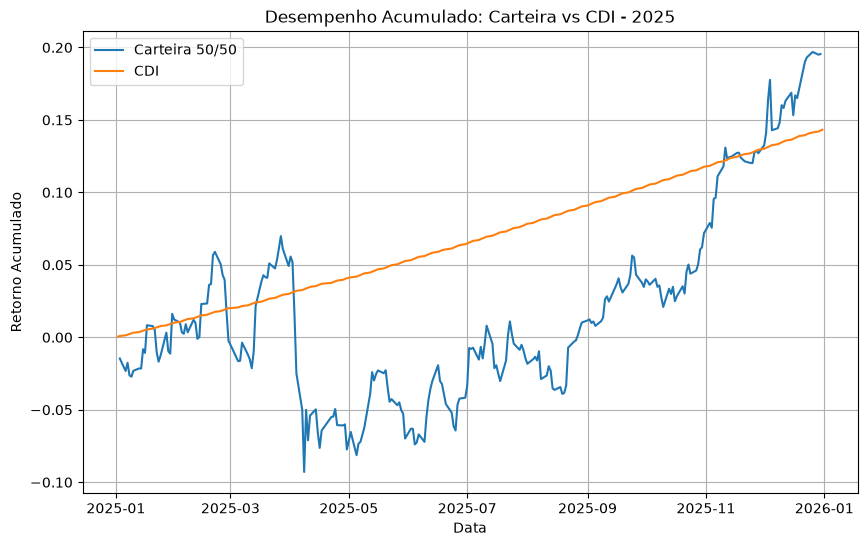

In [29]:
plt.figure(figsize=(10, 6))

plt.plot(
    retorno_acumulado_carteira.index,
    retorno_acumulado_carteira,
    label="Carteira 50/50"
)

plt.plot(
    retorno_acumulado_cdi.index,
    retorno_acumulado_cdi,
    label="CDI"
)

plt.title("Desempenho Acumulado: Carteira vs CDI - 2025")
plt.xlabel("Data")
plt.ylabel("Retorno Acumulado")
plt.legend()
plt.grid()

plt.show()

## Drawdown da Carteira

O drawdown mostra quanto a carteira caiu em relação ao seu maior valor acumulado anterior.

Quanto mais negativo o valor, maior foi a queda sofrida pela carteira.

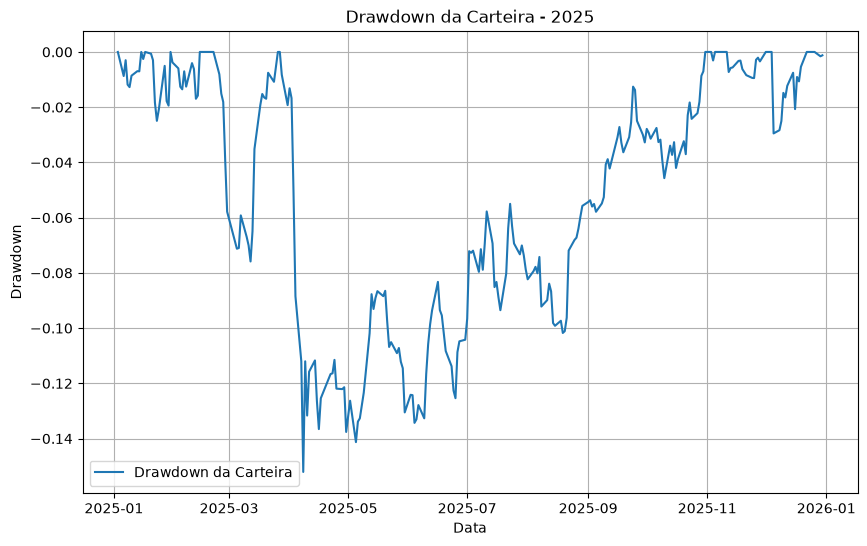

In [30]:
drawdown_carteira = calcular_drawdown(retornos_carteira)

plt.figure(figsize=(10, 6))

plt.plot(
    drawdown_carteira.index,
    drawdown_carteira,
    label="Drawdown da Carteira"
)

plt.title("Drawdown da Carteira - 2025")
plt.xlabel("Data")
plt.ylabel("Drawdown")
plt.legend()
plt.grid()

plt.show()

## Conclusão

O projeto permitiu aplicar conceitos básicos de Python e análise financeira utilizando dados reais do mercado brasileiro.

Foram analisados:

- PETR4
- VALE3
- BOVA11
- CDI
- Carteira 50% PETR4 e 50% VALE3

As principais métricas utilizadas foram retorno, volatilidade, Sharpe Ratio, correlação e drawdown.

O notebook complementa o arquivo `main.py`, permitindo visualizar cada etapa da análise separadamente.